# Propagation Analysis

In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib widget

In [2]:
from itertools import product
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.fft import irfft, rfft, ifftshift
from scipy.signal import ShortTimeFFT, welch
from scipy.signal.windows import hann
from tqdm import tqdm
from tritonoa.modeling.at.kraken import run_kraken
from tritonoa.modeling.physics import propagate_signal
from tritonoa.signal import waveforms
from tritonoa.signal.util import get_freqs_from_band

from rodeo import model as mdl, plotting, utils

plt.style.use(Path("config/jasa_fig_style.mplstyle"))

SAVEPATH = Path.cwd() / "results"

## Load SSP

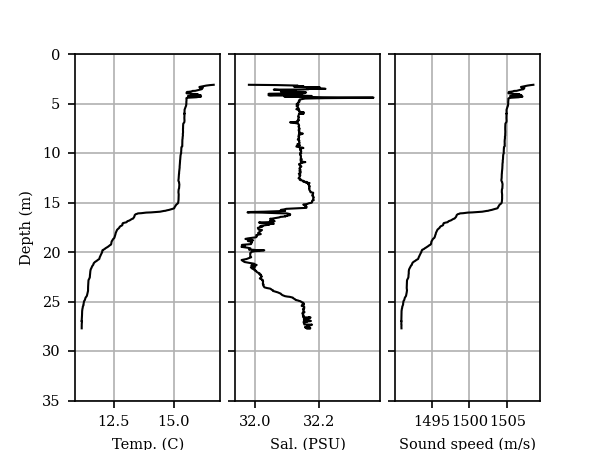

In [3]:
ctd_file = Path("data/ctd/sfw_leg1_2023-06-23/Casts/RBR203246_data.txt")
ctd_df = utils.clean_ctd_data(pd.read_csv(ctd_file, parse_dates=["Time"]), min_depth=1.0)
ctd_df = ctd_df.iloc[700:1300].sort_values("Depth")

plot_kwargs = {
    "Temperature": {"label": "Temperature", "color": "black"},
    "Salinity": {"label": "Salinity", "color": "black"},
    "Speed of sound": {"label": "Speed of sound", "color": "black"},
}
fig = plotting.plot_ctd_profiles(ctd_df, **plot_kwargs)

## Create environment model w/ SSP data

In [4]:
environment = mdl.construct_environment()
layerdata = environment["layerdata"]
z = ctd_df["Depth"].values
c_p = ctd_df["Speed of sound"].values
z = np.append(z, layerdata[0]["z"].max())
c_p = np.append(c_p, c_p[-1])
z = np.insert(z, 0, 0.0)
c_p = np.insert(c_p, 0, layerdata[0]["c_p"])

new_layerdata = [
    {"z": z, "c_p": c_p},
    layerdata[1],
]
environment.update({"layerdata": new_layerdata})

## Mode Function

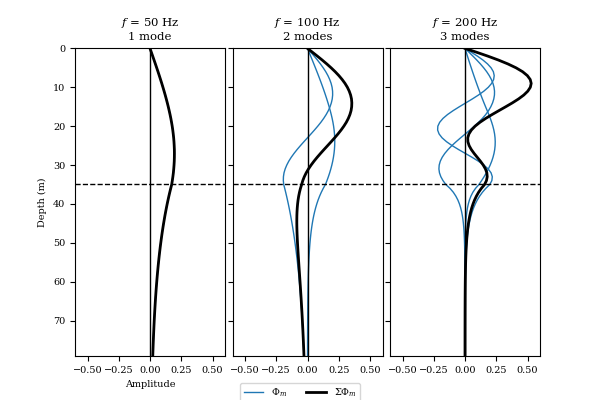

In [5]:
freqs = [50.0, 100.0, 200.0]
zgrid = np.arange(0, 80, 1)
environment.update({"rec_z": zgrid})
phis = []
for freq in freqs:
    model = run_kraken(environment | {"freq": freq})
    phis.append(model.modes.phi_rec)

fig = plotting.plot_mode_function(environment, phis, freqs, zgrid)
fig.savefig(SAVEPATH / "mode_function.png", dpi=600, bbox_inches="tight", facecolor="w")
plt.show()

## Predicted pressure fields at VLA1 & VLA2

In [6]:
freqs = np.arange(40, 200, 1)
source_depths = np.arange(0, 45, 0.5)

pressures = []
for station, dist in {"VLA 1": 3.9, "VLA 2": 9.4}.items():
    print(f"Station {station}")
    pressure = np.zeros((len(freqs), len(source_depths), len(zgrid)), dtype=complex)
    for (i, freq), (j, src_depth) in product(enumerate(freqs), enumerate(source_depths)):
        model = run_kraken(environment | {"freq": freq, "src_z": src_depth, "rec_r": dist})
        pressure[i, j] = model.modes.p.squeeze()
    pressure = pressure.sum(axis=(0, 1))
    pressures.append(pressure)
print("Complete.")

Station VLA 1
Station VLA 2
Complete.


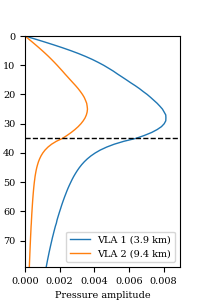

In [9]:
fig = plotting.plot_pressure_fields(pressures, zgrid, 35.0, labels=["VLA 1 (3.9 km)", "VLA 2 (9.4 km)"])
fig.savefig(SAVEPATH / "pressure_fields.png", dpi=600, bbox_inches="tight", facecolor="w")
plt.show()

## Pulse Propagation

In [ ]:
def plot_orig_and_dispersed(t, x, y):
    fig, axs = plt.subplots(nrows=2)
    ax = axs[0]
    ax.plot(t, x)
    ax.set_xlim(t[0], t[-1])
    ax.set_xlabel("Time (s)")
    ax.set_ylabel("Pressure (Pa)")
    ax = axs[1]
    ax.plot(t, y)
    ax.set_xlim(t[0], t[-1])
    ax.set_xlabel("Reduced time (s)")
    ax.set_ylabel("Pressure (Pa)")
    fig.tight_layout()
    return fig

In [ ]:
factor = 2.0
fc = 100.0 * factor
# bw = 195.0
T = 40 / fc * factor
fs = 8192.0 * 2
pulse = waveforms.generate_gaussian_pulse(T, fc, fs, sigma=0.01)
# pulse = waveforms.generate_cw(T, fc, fs)

dt = 1 / fs
t = np.arange(0, T - dt, dt)


# factor = 1.0
# fc = 100.0 * factor
# bw = 100.0
# pulse_dur = 4 / fc * factor
fl = 40
fu = 1000
# fs = 8192.0
# pulse = waveforms.generate_cw(pulse_dur, fc, fs)
window = hann(len(pulse))
pulse *= window
T = 1.0
t = np.arange(0, T, 1 / fs)
N = t.size
x = np.concatenate([pulse, np.zeros(N - pulse.size)])
x += np.random.normal(0, 1e-8, N)

# Define frequencies
freqs, inds = get_freqs_from_band(len(x), [fl, fu], fs=fs)

# Define the environment
environment = construct_environment()

# Expected travel time:
c_max = 1500.0
t_offset = environment["rec_r"] * 1e3 / c_max

# Compute Green's Function
p = np.zeros((len(freqs),), dtype=complex)
for i, freq in tqdm(enumerate(freqs), total=len(freqs)):
    model = run_kraken(environment | {"freq": freq})
    p[i] = model.modes.p.squeeze()

# Propagate signal
y = propagate_signal(x, p, freqs, inds, t_offset, nfft=N)

fig = plot_orig_and_dispersed(t, x, y)
plt.show()



In [ ]:
h = irfft(np.abs(p) ** 2, )
plt.figure()
plt.plot(np.arange(len(h)) / fs, h)
plt.show()

In [ ]:
M = 512
pcoverlap = 0.9
win = hann(M)
SFT = ShortTimeFFT(win, hop=int((1 - pcoverlap) * M), mfft=8*M, fs=fs, scale_to="psd")
Sx = SFT.stft(x)
Sy = SFT.stft(y)
Sx = 10 * np.log10(np.abs(Sx) ** 2)
Sy = 10 * np.log10(np.abs(Sy) ** 2)

t = SFT.t(len(x))

In [ ]:
ylim = (10, 1000)

fig, axs = plt.subplots(ncols=2, figsize=(6, 3), gridspec_kw={"wspace": 0.07})
ax = axs[0]
# im = ax.imshow(Sx, aspect="auto", origin="lower", extent=SFT.extent(len(x)), interpolation="none")
im = ax.pcolormesh(t, SFT.f, Sx[0:-1, 0:-1], shading="flat")
ax.set_yscale("log")
ax.set_ylim(ylim)
ax.set_xlabel("Reduced time (s)")
ax.set_ylabel("Frequency (Hz)")

ax = axs[1]
im = ax.pcolormesh(t, SFT.f, Sy[0:-1, 0:-1], shading="flat")
ax.set_yscale("log")
ax.set_ylim(ylim)
ax.set_yticklabels([])

plt.show()

# TODO: Figure out how to adjust extent more easily

In [ ]:
f, Pxx = welch(x, fs=fs, nperseg=4096, noverlap=2048)
_, Pyy = welch(y, fs=fs, nperseg=4096, noverlap=2048)

Pxx = 10 * np.log10(Pxx / np.max(np.abs(Pxx)))
Pyy = 10 * np.log10(Pyy / np.max(np.abs(Pyy)))

fig = plt.figure()
plt.plot(f, Pxx, c="tab:blue", label="Original")
plt.plot(f, Pyy, c="tab:orange", label="Dispersed")
plt.xscale("log")
plt.grid(True)
plt.xlim(10, 10000)
plt.xlabel("Frequency (Hz)")
plt.ylabel("Power spectral density (dB/Hz)")
plt.legend()
plt.show()